# Discriminación fuera de muestra y estudio de ablación

Ejecutar desde la raíz del proyecto con las versiones archivadas y XGBoost 2.1.4. El ZIP de la auditoría de datos aporta la base limpia y los índices archivados. Se reutilizan los tres modelos ya ajustados. El XGBoost faltante se obtiene con la búsqueda interna de hiperparámetros (16 candidatos, cinco pliegues estratificados, ROC-AUC, semilla 42) exclusivamente en entrenamiento. La primera sección termina con los modelos, las variantes y los umbrales fijados.

El criterio de selección para la ablación es el mayor ROC-AUC en validación, con AP y luego menor Log Loss como desempates. Para cada bloque se muestra el desempeño aislado y la caída al retirarlo del modelo completo. La logística conserva las transformaciones e interacciones de M5 que tienen todos sus predictores disponibles. D reutiliza el modelo ajustado con toda la información. La F1 de la ablación usa 0.50.

In [1]:
from importlib.metadata import version
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import sys

root = Path.cwd()
if not (root / "src" / "evaluation.py").is_file():
    root = root.parent
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

from src.evaluation import (
    ablation_deltas, compare_test_predictions, paired_auc_difference,
    plot_ablation, plot_test_confusions, plot_test_curves, prediction_frame,
    probability_metrics, score_ablation, stratified_auc_bootstrap,
    summarize_search, youden_threshold,
)
from src.models import Phase4Logistic, fit_ablation_model, load_model, optimize_model, save_model
from src.preprocessing import BILLS, CATEGORICAL, PAYMENT_STATUS, PAYMENTS, load_and_split

archive_path = root / "sources" / "phase1_deliverables.zip"
reports = root / "reports"
figures = root / "figures"
frozen_dir = reports / "phase6_models"
frozen_dir.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)
archive_report = json.loads((reports / "phase5_results.json").read_text(encoding="utf-8"))
for package, expected in archive_report["versiones"].items():
    assert version(package) == expected, (package, expected)
assert version("xgboost") == "2.1.4"

splits = load_and_split(archive_path)
X_train, y_train = splits["train"]
X_val, y_val = splits["val"]
with ZipFile(archive_path) as archive:
    archived_indices = archive.read("data/phase1/split_indices.npz")
with np.load(BytesIO(archived_indices)) as archived:
    np.testing.assert_array_equal(X_train.index, archived["train"])
    np.testing.assert_array_equal(X_val.index, archived["validation"])
assert len(y_train) == 21_000 and len(y_val) == 4_500
print(f"Entrenamiento {len(y_train):,} · Validación {len(y_val):,}")

Entrenamiento 21,000 · Validación 4,500


In [2]:
labels = {
    "prob_logreg": "Regresión logística", "prob_dt": "Árbol de decisión",
    "prob_rf": "Random Forest", "prob_xgb": "XGBoost",
}
phase5_names = {"prob_logreg": "logistic", "prob_dt": "tree", "prob_rf": "forest"}
paths = {name: reports / "phase5_models" / f"{key}.joblib" for name, key in phase5_names.items()}
paths["prob_xgb"] = frozen_dir / "xgboost.joblib"
xgb_cv_path = frozen_dir / "xgboost_cv.json"
if not (paths["prob_xgb"].is_file() and xgb_cv_path.is_file()):
    search = optimize_model("xgboost", X_train, y_train, n_jobs=4)
    save_model(search.best_estimator_, paths["prob_xgb"])
    xgb_cv_path.write_text(json.dumps(summarize_search(search), indent=2, ensure_ascii=False),
                           encoding="utf-8")
models = {name: load_model(path) for name, path in paths.items()}
assert models["prob_xgb"]["model"].get_params()["objective"] == "binary:logistic"

with threadpool_limits(limits=1):
    val = prediction_frame(models, X_val, y_val)
validation = pd.DataFrame({name: probability_metrics(y_val, val[name]) for name in labels}).T
for name, key in phase5_names.items():
    for metric in validation.columns:
        np.testing.assert_allclose(validation.at[name, metric], archive_report["val"][key][metric],
                                   rtol=0, atol=1e-12)
ranking = validation.sort_values(["ROC-AUC", "PR-AUC (AP)", "Log Loss"],
                                 ascending=[False, False, True])
winner = ranking.index[0]
thresholds = {name: youden_threshold(y_val, val[name]) for name in labels}
val.to_csv(reports / "06_probabilities_val.csv", index=False)
display(ranking.rename(index=labels))
display(pd.Series(thresholds, name="Umbral Youden en validación").rename(index=labels))
print("Modelo elegido para ablación:", labels[winner])

Modelo elegido para ablación: XGBoost


,ROC-AUC,PR-AUC (AP),Log Loss,Brier Score
XGBoost,0.779613,0.554466,0.430305,0.135453
Random Forest,0.775379,0.548156,0.432604,0.136337
Árbol de decisión,0.756509,0.517920,0.446186,0.139746
Regresión logística,0.719080,0.498975,0.463093,0.144229


Regresión logística    0.289052
Árbol de decisión      0.226852
Random Forest          0.234978
XGBoost                0.207790
Name: Umbral Youden en validación, dtype: float64

In [3]:
blocks = {
    "A": [*CATEGORICAL, "AGE"],
    "B": PAYMENT_STATUS,
    "C": ["LIMIT_BAL", *BILLS, *PAYMENTS],
}
variants = {**blocks, "D": X_train.columns.tolist()}
for block in blocks:
    variants[f"sin {block}"] = [
        column for column in variants["D"] if column not in blocks[block]
    ]
ablation_names = list(dict.fromkeys([winner, "prob_logreg"]))
ablation_models = {
    (name, variant): fit_ablation_model(models[name], X_train, y_train, columns)
    for name in ablation_names
    for variant, columns in variants.items()
    if variant != "D"
}
manifest = {
    "seed": 42, "bootstrap_replicates": 1000,
    "train_val_test_sizes": [21000, 4500, 4500],
    "classification_cutoffs": {"standard": 0.5, "youden_val": thresholds},
    "ablation_winner_from_validation": winner, "ablation_cutoff": 0.5,
    "ablation_features": variants,
    "versions": {**archive_report["versiones"], "xgboost": version("xgboost")},
    "model_sha256": {name: hashlib.sha256(path.read_bytes()).hexdigest()
                     for name, path in paths.items()},
    "xgboost_train_cv": json.loads(xgb_cv_path.read_text(encoding="utf-8")),
}
(reports / "06_frozen_protocol.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8",
)
print("Protocolo congelado. Variantes entrenadas:", len(ablation_models))

Protocolo congelado. Variantes entrenadas: 12


## Evaluación en prueba

Se genera un vector de probabilidades por modelo y variante. Todas las métricas, curvas y réplicas se calculan a partir de esas predicciones. Las matrices se normalizan por clase observada, en orden cumple e incumple. El contraste bilateral bootstrap está centrado en la diferencia observada. Comparar a los dos primeros de prueba es un análisis exploratorio por la selección en el mismo conjunto. También se muestra el contraste para la pareja fijada por el ranking de validación si difiere en orden o integrantes.

In [4]:
X_test, y_test = splits["test"]
with np.load(BytesIO(archived_indices)) as archived:
    np.testing.assert_array_equal(X_test.index, archived["test"])
assert len(y_test) == 4_500
with threadpool_limits(limits=1):
    test = prediction_frame(models, X_test, y_test)
    ablation_predictions = {}
    for name in ablation_names:
        for variant, columns in variants.items():
            if variant == "D":
                ablation_predictions[name, variant] = test[name].to_numpy()
                continue
            model = ablation_models[name, variant]
            p = np.asarray(model.predict_proba(X_test.loc[:, columns]), dtype=float)
            ablation_predictions[name, variant] = p if isinstance(model, Phase4Logistic) else p[:, 1]
test.to_csv(reports / "06_probabilities_test.csv", index=False)
print(f"Incumplimientos {y_test.sum()} / {len(y_test)} · Prevalencia {y_test.mean():.12f}")

Incumplimientos 996 / 4500 · Prevalencia 0.221333333333


In [5]:
replicas = stratified_auc_bootstrap(test, n_replicates=1000, seed=42)
probability, classification, matrices = compare_test_predictions(test, thresholds, replicas)
ablation = score_ablation(y_test, ablation_predictions)
deltas = ablation_deltas(ablation, blocks)
top_test = tuple(probability["ROC-AUC"].nlargest(2).index)
top_val = tuple(ranking.index[:2])
pairs = {"dos mejores en test (exploratorio)": top_test}
if top_val != top_test:
    pairs["pareja fijada en val"] = top_val
paired = pd.DataFrame({
    label: paired_auc_difference(replicas, first, second,
                                 probability.at[first, "ROC-AUC"] - probability.at[second, "ROC-AUC"])
    for label, (first, second) in pairs.items()
}).T
normalized = pd.DataFrame([
    {"modelo": name, "regla": rule, **dict(zip(["TN", "FP", "FN", "TP"], rates.ravel()))}
    for (name, rule), (_, rates) in matrices.items()
])
for filename, table in {
    "probability_metrics": probability, "classification_metrics": classification.set_index(["modelo", "regla"]),
    "confusion_normalized": normalized.set_index(["modelo", "regla"]),
    "paired_auc": paired, "ablation_metrics": ablation, "ablation_deltas": deltas,
}.items():
    table.to_csv(reports / f"06_{filename}.csv")

display(probability.rename(index=labels))
display(classification.replace({"modelo": labels})[
    ["modelo", "regla", "umbral", "Accuracy", "Precisión", "Sensibilidad", "F1"]
])
for (name, rule), (counts, rates) in matrices.items():
    print(labels[name], rule, "\nAbsoluta\n", counts, "\nNormalizada por fila\n", rates)
display(paired.assign(primero=paired["primero"].map(labels), segundo=paired["segundo"].map(labels)))
display(ablation.rename(index=labels, level="modelo"))
display(deltas.rename(index=labels, level="modelo"))

Regresión logística 0.50 
Absoluta
 [[3375  129]
 [ 699  297]] 
Normalizada por fila
 [[0.96318493 0.03681507]
 [0.70180723 0.29819277]]
Regresión logística Youden val 
Absoluta
 [[3118  386]
 [ 519  477]] 
Normalizada por fila
 [[0.88984018 0.11015982]
 [0.52108434 0.47891566]]
Árbol de decisión 0.50 
Absoluta
 [[3332  172]
 [ 651  345]] 
Normalizada por fila
 [[0.95091324 0.04908676]
 [0.65361446 0.34638554]]
Árbol de decisión Youden val 
Absoluta
 [[2586  918]
 [ 336  660]] 
Normalizada por fila
 [[0.7380137 0.2619863]
 [0.3373494 0.6626506]]
Random Forest 0.50 
Absoluta
 [[3331  173]
 [ 649  347]] 
Normalizada por fila
 [[0.95062785 0.04937215]
 [0.65160643 0.34839357]]
Random Forest Youden val 
Absoluta
 [[2820  684]
 [ 374  622]] 
Normalizada por fila
 [[0.80479452 0.19520548]
 [0.37550201 0.62449799]]
XGBoost 0.50 
Absoluta
 [[3328  176]
 [ 642  354]] 
Normalizada por fila
 [[0.94977169 0.05022831]
 [0.64457831 0.35542169]]
XGBoost Youden val 
Absoluta
 [[2719  785]
 [ 345  651]

,ROC-AUC,PR-AUC (AP),Log Loss,Brier Score,ROC IC95 inferior,ROC IC95 superior,AP − prevalencia
modelo,,,,,,,
Regresión logística,0.729419,0.502144,0.460576,0.143206,0.709731,0.748904,0.280811
Árbol de decisión,0.762831,0.526203,0.444604,0.138518,0.745784,0.779989,0.304870
Random Forest,0.781706,0.560090,0.428339,0.134439,0.765515,0.798678,0.338757
XGBoost,0.783437,0.564031,0.427138,0.134122,0.766859,0.800058,0.342698


,modelo,regla,umbral,Accuracy,Precisión,Sensibilidad,F1
0,Regresión logística,0.50,0.500000,0.816000,0.697183,0.298193,0.417722
1,Regresión logística,Youden val,0.289052,0.798889,0.552723,0.478916,0.513179
2,Árbol de decisión,0.50,0.500000,0.817111,0.667311,0.346386,0.456048
3,Árbol de decisión,Youden val,0.226852,0.721333,0.418251,0.662651,0.512821
4,Random Forest,0.50,0.500000,0.817333,0.667308,0.348394,0.457784
5,Random Forest,Youden val,0.234978,0.764889,0.476263,0.624498,0.540400
6,XGBoost,0.50,0.500000,0.818222,0.667925,0.355422,0.463958
7,XGBoost,Youden val,0.207790,0.748889,0.453343,0.653614,0.535362


,primero,segundo,delta,ic95_inferior,ic95_superior,p_bilateral
dos mejores en test (exploratorio),XGBoost,Random Forest,0.001731,-0.001897,0.005353,0.357642


ROC-AUC  PR-AUC (AP)  Log Loss        F1
modelo              variante                                           
XGBoost             A         0.578218     0.266767  0.521833  0.000000
                    B         0.744025     0.530290  0.442683  0.451485
                    C         0.731884     0.449401  0.467491  0.269051
                    D         0.783437     0.564031  0.427138  0.463958
                    sin A     0.780098     0.553979  0.429852  0.455145
                    sin B     0.734362     0.447705  0.466421  0.260465
                    sin C     0.757505     0.550511  0.438649  0.456579
Regresión logística A         0.558609     0.259621  0.523490  0.000000
                    B         0.703682     0.483191  0.475389  0.338415
                    C         0.646926     0.327308  0.509365  0.000000
                    D         0.729419     0.502144  0.460576  0.417722
                    sin A     0.719996     0.495189  0.464272  0.417784
                    sin B     0.658348     0.332216  0.504929  0.007960
                    sin C     0.708980     0.496360  0.471876  0.351249

Δ ROC-AUC  Δ PR-AUC (AP)
modelo              bloque contraste                                      
XGBoost             A      D − bloque aislado      0.205220       0.297264
                           D − modelo sin bloque   0.003339       0.010052
                    B      D − bloque aislado      0.039413       0.033741
                           D − modelo sin bloque   0.049076       0.116326
                    C      D − bloque aislado      0.051553       0.114630
                           D − modelo sin bloque   0.025932       0.013520
Regresión logística A      D − bloque aislado      0.170810       0.242523
                           D − modelo sin bloque   0.009423       0.006955
                    B      D − bloque aislado      0.025737       0.018953
                           D − modelo sin bloque   0.071070       0.169928
                    C      D − bloque aislado      0.082493       0.174836
                           D − modelo sin bloque   0.020439       0.005783

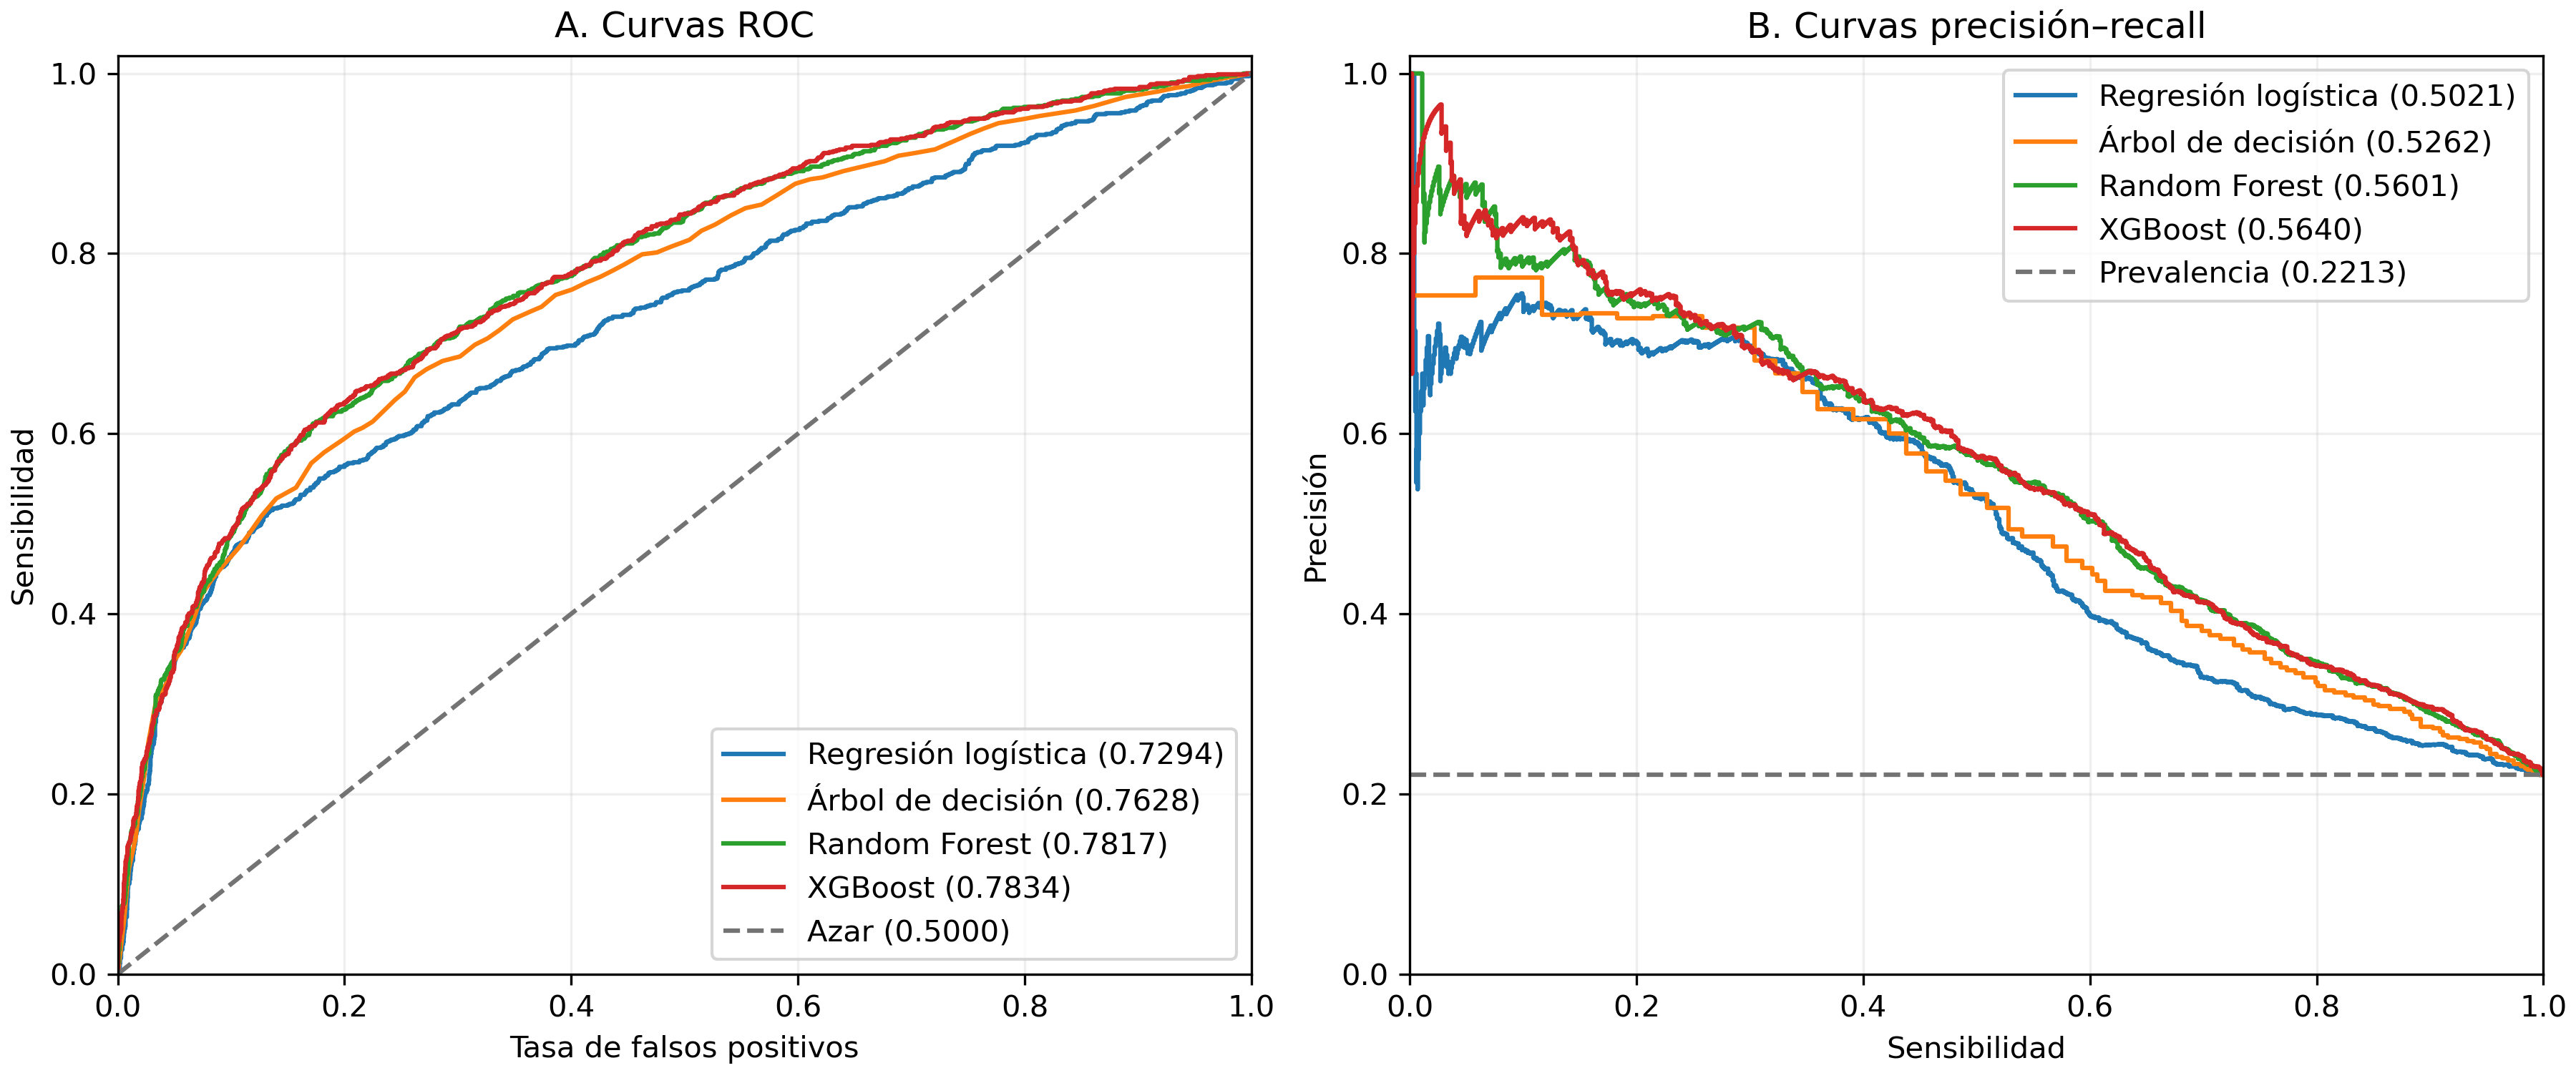

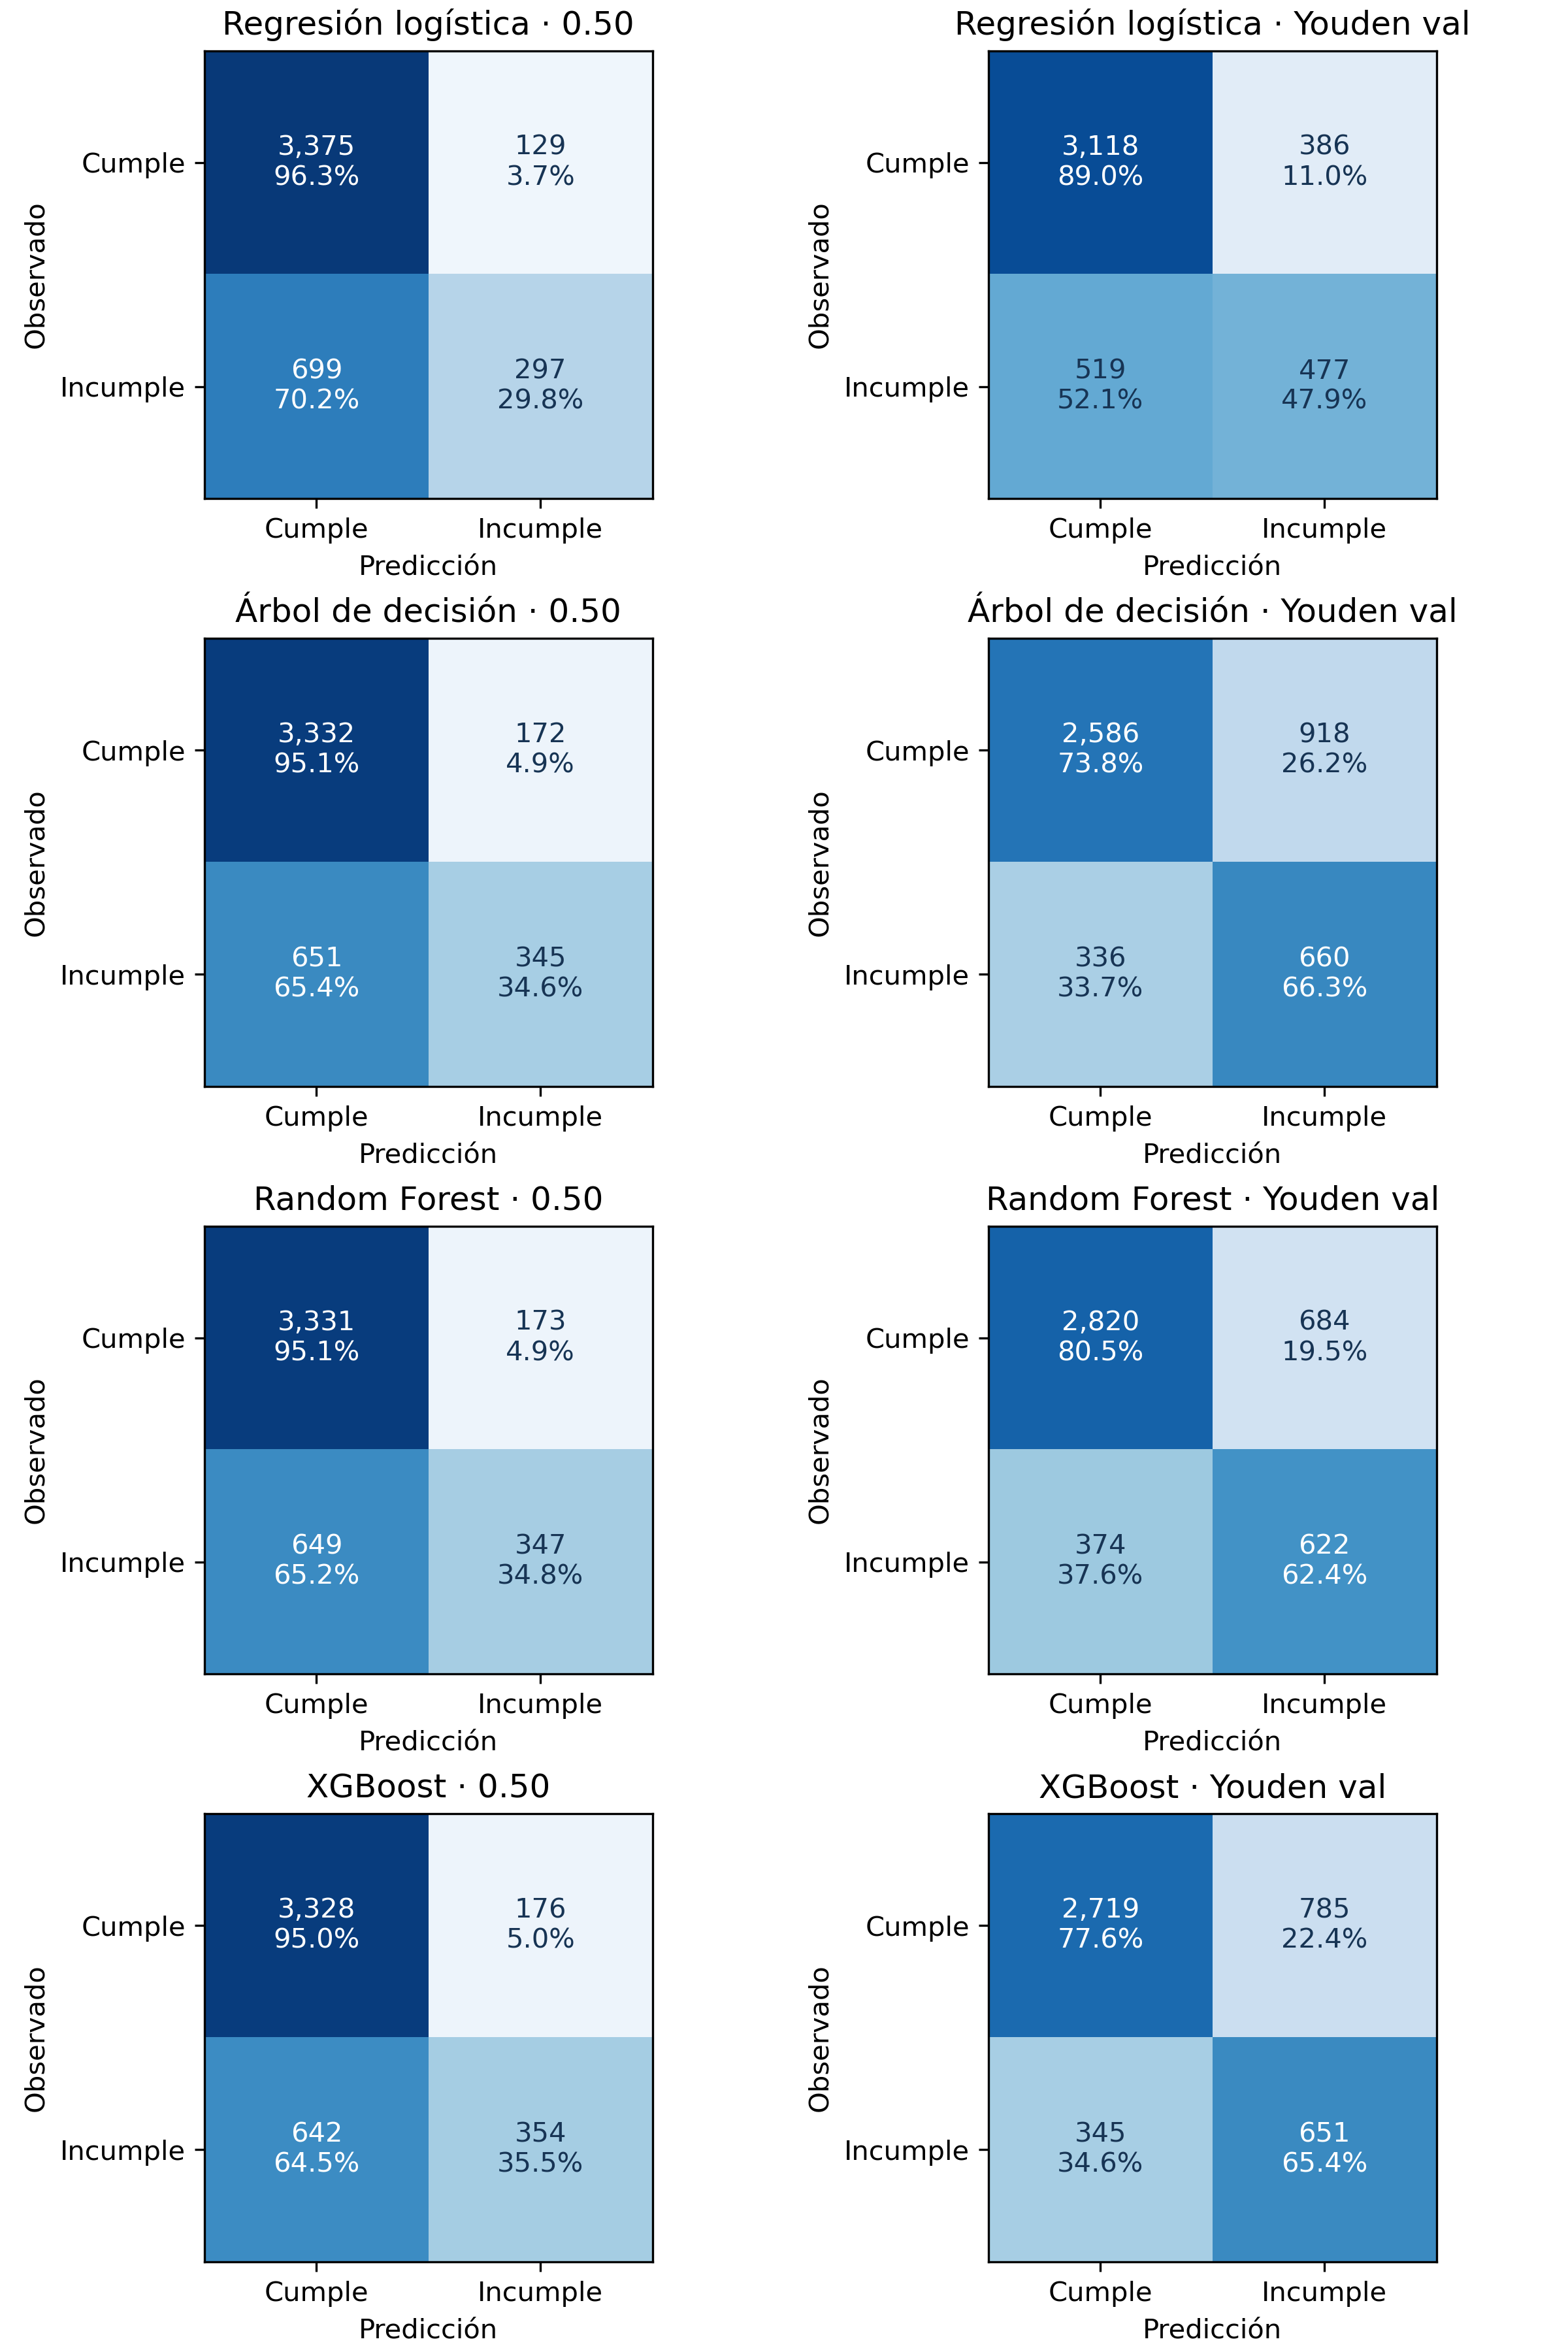

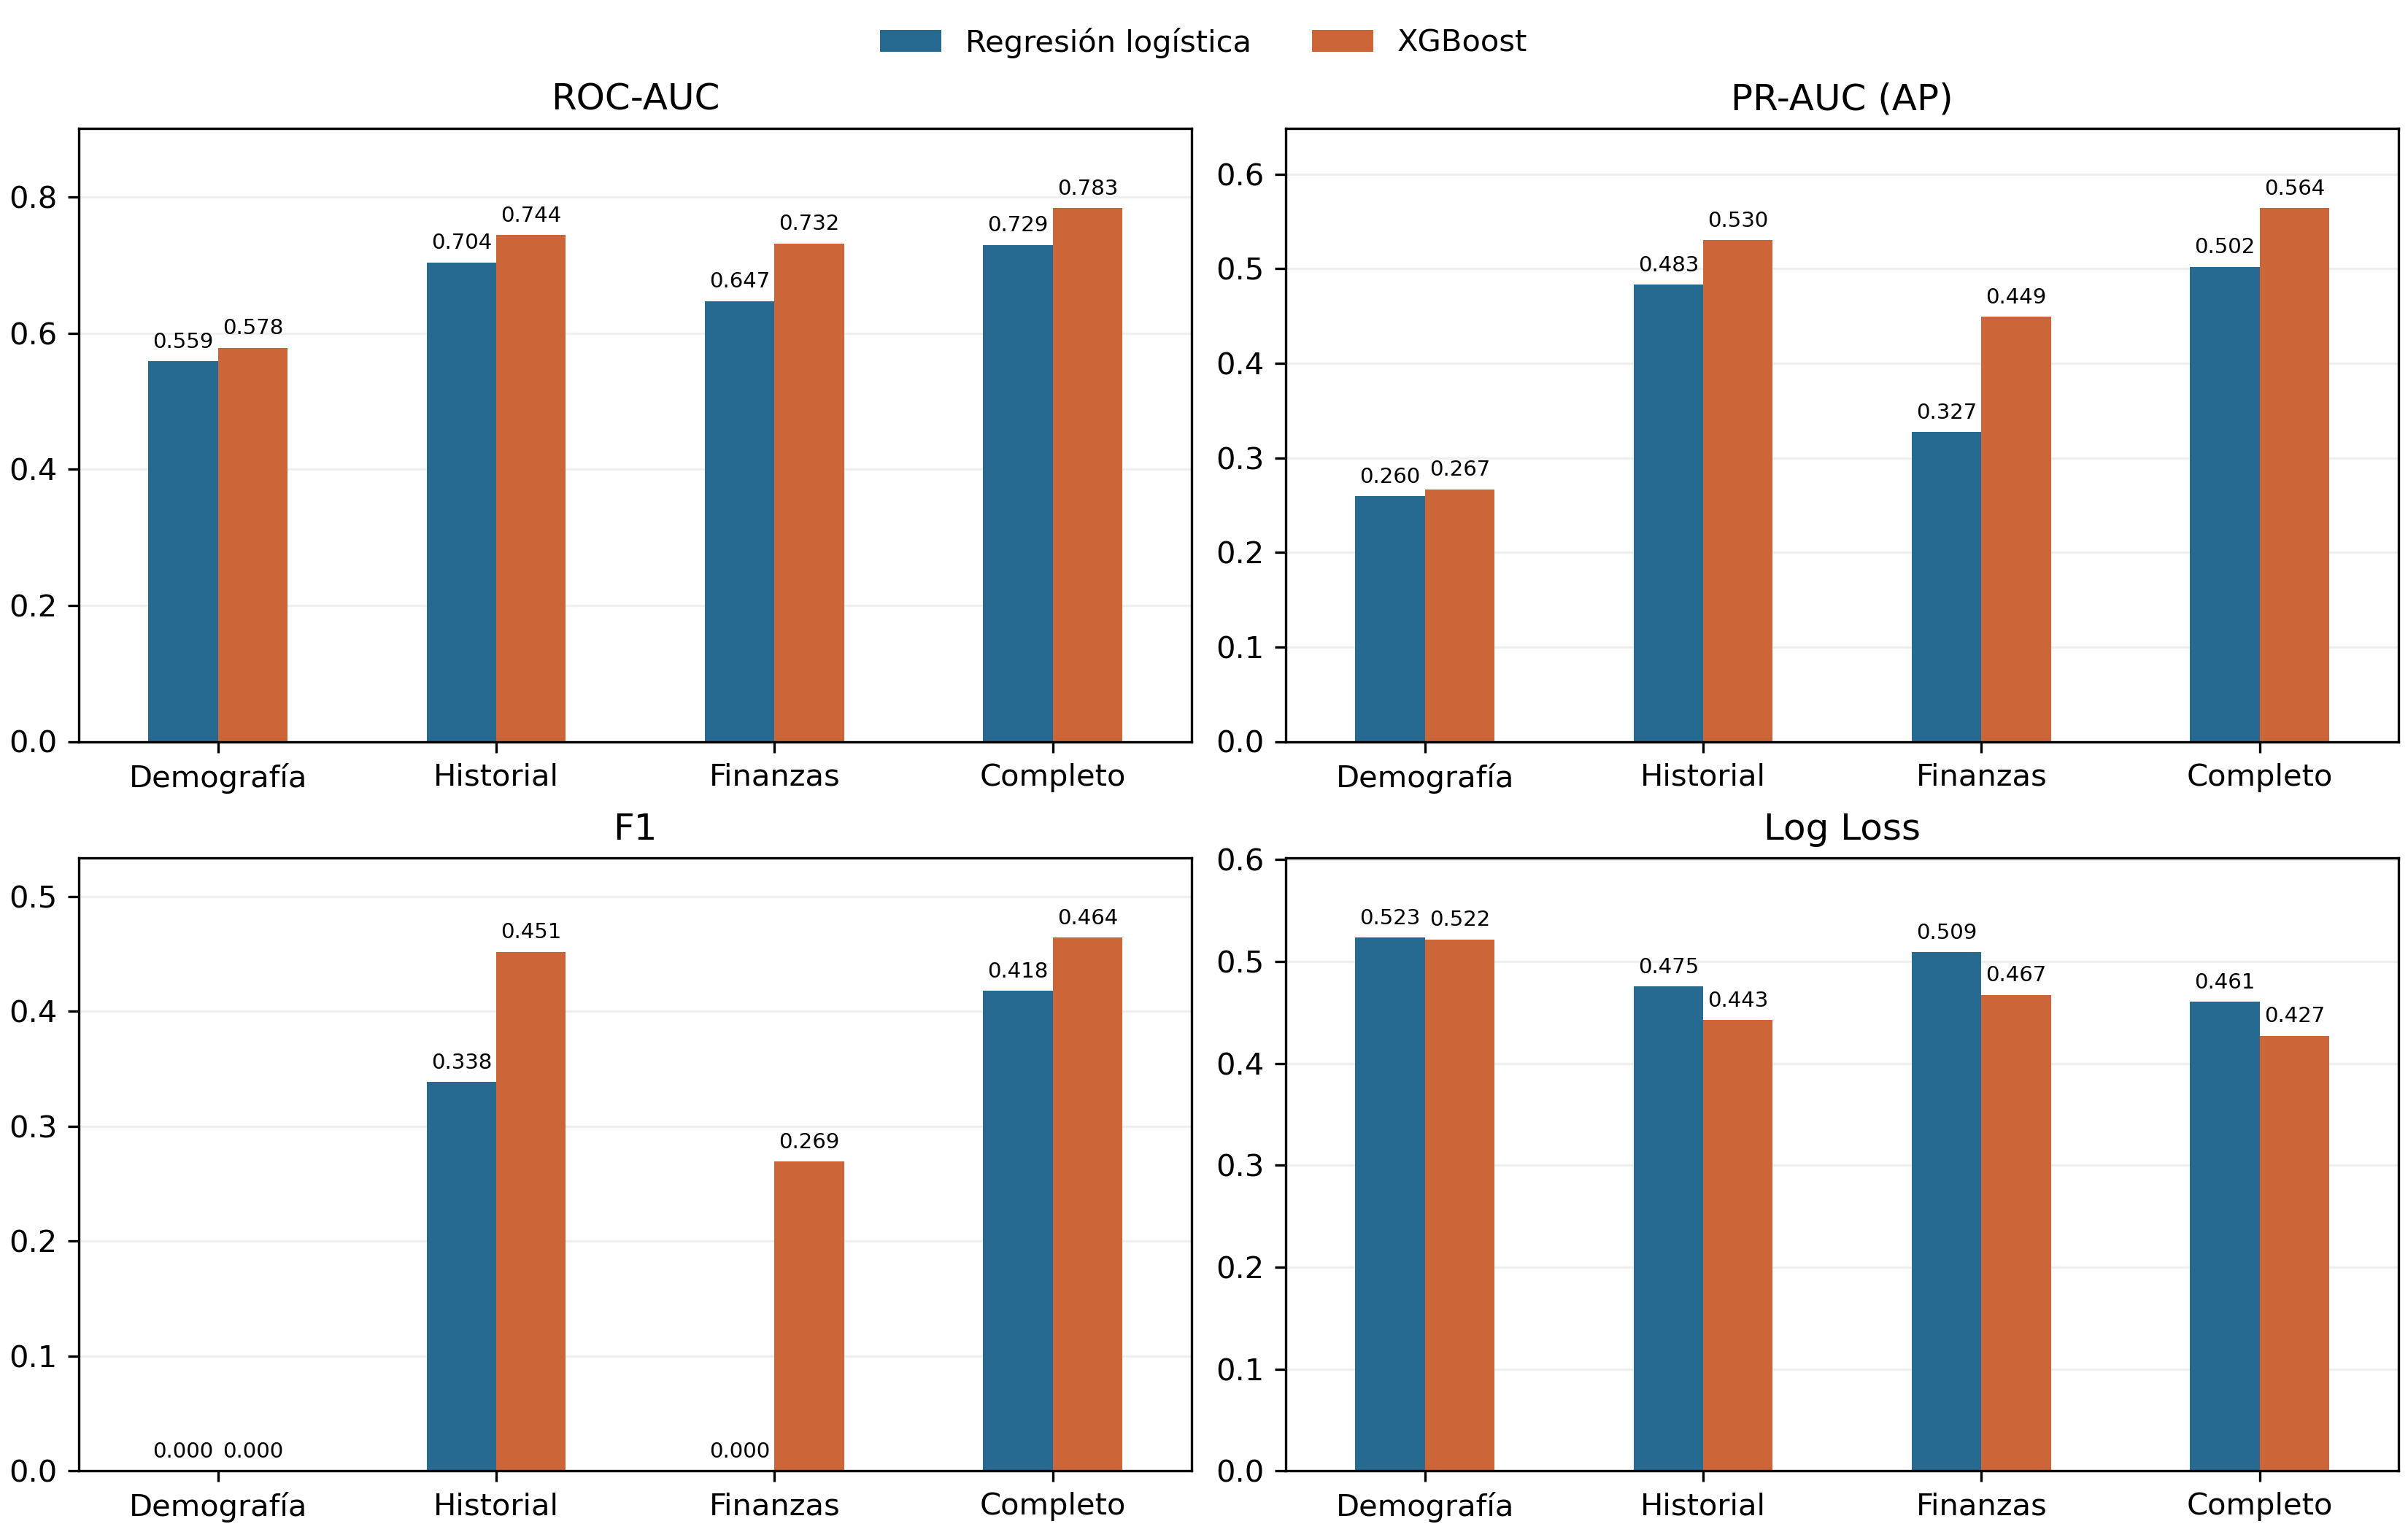

In [6]:
for filename, fig in [
    ("08_test_roc_pr_curves.png", plot_test_curves(test, probability, labels)),
    ("09_test_confusion_matrices.png", plot_test_confusions(matrices, labels)),
    ("10_ablation_study_comparison.png", plot_ablation(ablation, labels)),
]:
    fig.savefig(figures / filename, dpi=300, facecolor="white")
    plt.close(fig)
    display(Image(filename=figures / filename, width=850))

## Interpretación

XGBoost y Random Forest ocuparon los dos primeros puestos en ROC-AUC tanto en validación como en prueba. La diferencia en prueba fue 0.001731 (IC 95% bootstrap pareado de −0.001897 a 0.005353, p = 0.357642). XGBoost también obtuvo el mayor AP y las menores pérdidas probabilísticas. Random Forest obtuvo la mayor F1 al aplicar los cortes elegidos con Youden en validación.

El historial de pagos obtuvo el mejor desempeño como bloque aislado y su retiro produjo la mayor caída de ROC-AUC y de AP en ambos modelos de ablación. Los contrastes cuantifican información predictiva condicional al modelo y sus hiperparámetros. Los resultados reflejan asociaciones en clientes de Taiwán en 2005. Su aplicación en Colombia requeriría validación en una población local.

## Calibración probabilística, auditoría demográfica y pérdida esperada

Esta sección se ejecuta de forma autónoma con las PD congeladas de la evaluación comparativa. Verifica la partición archivada (estratificada, seed 42, 21.000/4.500/4.500) y las etiquetas de las predicciones exportadas. Los modelos y su preprocesamiento provienen de los ajustes sobre entrenamiento.

El ROC-AUC de validación selecciona los dos candidatos discriminantes. Se incluye la regresión logística como referencia. Platt ajusta una sigmoide logística de la PD cruda. La regresión isotónica ajusta una función no decreciente. Se selecciona la variante calibrada con menor Brier fuera de pliegue, con Log Loss como desempate, usando cinco pliegues estratificados de validación. El reajuste de cada calibrador usa los 4.500 pares de validación y las métricas finales usan los 4.500 clientes de prueba (996 incumplimientos).

El ECE pondera la brecha absoluta entre PD media y tasa observada. Se solicitan diez intervalos uniformes y diez por cuantiles. Los bordes cuantílicos repetidos se fusionan para preservar los empates. Para la partición de Murphy, se reemplaza cada PD por la media de su intervalo uniforme. Así, Brier agrupado = reliability − resolution + uncertainty. El residuo intra-bin es el Brier individual menos el agrupado. [Murphy (1973)](https://journals.ametsoc.org/configurable/content/journals%24002fapme%24002f12%24002f4%24002f1520-0450_1973_012_0595_anvpot_2_0_co_2.xml)

In [7]:
from pathlib import Path
import sys

from IPython.display import display

phase7_root = Path.cwd()
if not (phase7_root / "notebooks" / "phase7_calibration.py").is_file():
    phase7_root = phase7_root.parent
sys.path.insert(0, str(phase7_root))
from notebooks.phase7_calibration import LABELS, METHODS, run_phase7

phase7_results, phase7_protocol = run_phase7(phase7_root)
display(phase7_results["07_validation_ranking"].rename(index=LABELS).round(9))
display(phase7_results["07_validation_selection"].rename(
    index={**LABELS, **METHODS}
).round(9))
display(phase7_results["07_calibration_metrics"].rename(
    index={**LABELS, **METHODS}
).round(9))

,ROC-AUC,PR-AUC (AP),Log Loss,Brier Score
modelo,,,,
XGBoost,0.779613,0.554466,0.430305,0.135453
Random Forest,0.775379,0.548156,0.432604,0.136337
Árbol de decisión,0.756509,0.517920,0.446186,0.139746
Regresión logística,0.719080,0.498975,0.463093,0.144229


ROC-AUC  PR-AUC (AP)  Log Loss  Brier Score
modelo              método                                                    
XGBoost             Sin calibrar  0.779613     0.554466  0.430305     0.135453
                    Platt         0.778887     0.553173  0.435266     0.136586
                    Isotónica     0.774045     0.539581  0.445349     0.135614
Random Forest       Sin calibrar  0.775379     0.548156  0.432604     0.136337
                    Platt         0.774765     0.547170  0.437245     0.137414
                    Isotónica     0.770835     0.533762  0.448395     0.136622
Regresión logística Sin calibrar  0.719080     0.498975  0.463093     0.144229
                    Platt         0.718332     0.496841  0.457124     0.143279
                    Isotónica     0.714305     0.483585  0.471571     0.143149

ROC-AUC  ...  Delta ROC-AUC vs cruda
modelo              método                  ...                        
Regresión logística Sin calibrar  0.729419  ...                0.000000
Árbol de decisión   Sin calibrar  0.762831  ...                0.000000
Random Forest       Sin calibrar  0.781706  ...                0.000000
XGBoost             Sin calibrar  0.783437  ...                0.000000
                    Platt         0.783437  ...                0.000000
                    Isotónica     0.780367  ...               -0.003070
Random Forest       Platt         0.781706  ...                0.000000
                    Isotónica     0.780411  ...               -0.001295
Regresión logística Platt         0.729419  ...                0.000000
                    Isotónica     0.728899  ...               -0.000520

[10 rows x 14 columns]

### Calibración en prueba

XGBoost y Random Forest lideraron en ROC-AUC de validación (0,779613331 y 0,775379035). XGBoost isotónico obtuvo el menor Brier fuera de pliegue entre las opciones calibradas (0,135613821). Su referencia cruda obtuvo 0,135452583 en validación.

En prueba, la isotónica de XGBoost bajó ambos ECE (uniforme 0,010076360 → 0,009719856 y por cuantiles 0,013886649 → 0,011448892). ROC-AUC pasó de 0,783437403 a 0,780367045 y AP de 0,564031044 a 0,535202243. Los tramos planos generan empates en el orden. Platt conservó el ROC-AUC en los tres modelos. XGBoost crudo obtuvo el menor Brier (0,134122141) y Log Loss (0,427137539) de toda la comparación en prueba. XGBoost isotónico registró 0,134608099 y 0,442940406, respectivamente. La isotónica produjo dos errores con PD extremas, una predicción de 0 para un incumplimiento y una de 1 para un cumplimiento.

[Curvas e histograma, 300 DPI](../figures/11_calibration_curves_comparison.png) · [Métricas completas, CSV](../reports/07_calibration_metrics.csv)

In [8]:
phase7_audit = phase7_results["07_demographic_audit"]
display(phase7_audit.round(9))
print("Corte de Youden de la evaluación comparativa", phase7_protocol["youden_cruda_fase6"])
print("Decisiones distintas respecto a la evaluación comparativa", phase7_protocol["decisiones_distintas_corte_literal"])

n  defaults  tasa_observada  ...   FP   FN   TP
variable  grupo                                        ...               
SEX       Hombres      1766       448        0.253681  ...  323  160  288
          Mujeres      2734       548        0.200439  ...  462  185  363
EDUCATION Posgrado     1580       320        0.202532  ...  246  129  191
          Universidad  2086       477        0.228667  ...  373  145  332
          Secundaria    766       197        0.257180  ...  165   70  127
          Otros          68         2        0.029412  ...    1    1    1
MARRIAGE  Casado       2063       498        0.241396  ...  358  173  325
          Soltero      2383       489        0.205204  ...  410  170  319
          Otros          54         9        0.166667  ...   17    2    7
AGE       <30          1414       314        0.222065  ...  245   97  217
          30–45        2354       488        0.207307  ...  404  181  307
          >45           732       194        0.265027  ...  136   67  127

[12 rows x 13 columns]

Corte de Youden de la evaluación comparativa 0.20779038965702057
Decisiones distintas respecto a la evaluación comparativa 0


### Auditoría por subgrupos

Se aplicó el corte de Youden de la evaluación comparativa (0,20779038965702057) a las PD calibradas. Las 4.500 decisiones coincidieron con las de la evaluación comparativa. El valor transformado del corte (0,24242424242424243) produjo las mismas decisiones en esta muestra. FPR usa como denominador los clientes que cumplieron y FNR usa quienes incumplieron.

La PD subestimó el incumplimiento medio de hombres en 2,04 puntos porcentuales y de mayores de 45 años en 2,24 puntos. En hombres y mujeres, la FPR fue 24,51% frente a 21,13% y la FNR 35,71% frente a 33,76%. Entre posgrado y universidad, la FNR fue 40,31% frente a 30,40%. Las categorías «Otros» de educación y estado civil registraron los mayores sesgos positivos (+7,01 y +9,93 puntos), con solo 2 y 9 incumplimientos. Los resultados son descriptivos y la precisión muestral de estos grupos es limitada.

[Auditoría demográfica, 300 DPI](../figures/12_demographic_fairness_audit.png) · [Métricas y conteos, CSV](../reports/07_demographic_audit.csv)

In [9]:
phase7_losses = phase7_results["07_expected_loss_scenarios"]
phase7_individual = phase7_results["07_expected_loss_individual"]
display(phase7_losses.round(9))
display(phase7_individual.head().round(6))

,LGD,CCF,n,ead_total_ntd,el_cruda_ntd,el_calibrada_ntd,delta_cal_menos_cruda_ntd,delta_relativo_a_calibrada,pd_cruda_ponderada_ead,pd_calibrada_ponderada_ead
escenario,,,,,,,,,,
Base,0.55,0.50,4500,497227726.0,4.930623e+07,4.883028e+07,-4.759565e+05,-0.009747,0.180295,0.178555
Adverso,0.70,0.75,4500,630705183.5,7.751581e+07,7.675200e+07,-7.638186e+05,-0.009952,0.175576,0.173846
Severo,0.85,1.00,4500,759657680.0,1.110208e+08,1.098901e+08,-1.130725e+06,-0.010290,0.171936,0.170185


,LIMIT_BAL,BILL_AMT1,pd_cruda,pd_calibrada,ead_base_ntd,el_cruda_base_ntd,el_calibrada_base_ntd,delta_base_ntd,ead_adverso_ntd,el_cruda_adverso_ntd,el_calibrada_adverso_ntd,delta_adverso_ntd,ead_severo_ntd,el_cruda_severo_ntd,el_calibrada_severo_ntd,delta_severo_ntd
fila_original_0based,,,,,,,,,,,,,,,,
25871,80000,4233,0.073524,0.066929,42116.5,1703.111613,1550.351476,-152.760137,61058.25,3142.465661,2860.603051,-281.862610,80000.0,4999.620736,4551.181102,-448.439633
26118,200000,38540,0.068825,0.066929,119270.0,4514.808879,4390.450787,-124.358092,159635.00,7690.801784,7478.962598,-211.839185,200000.0,11700.229570,11377.952756,-322.276814
15424,360000,245135,0.621085,0.671698,302567.5,103356.122273,111778.710377,8422.588104,331283.75,144028.823864,155765.868868,11737.045004,360000.0,190052.097559,205539.622642,15487.525083
23108,60000,46233,0.161566,0.183475,53116.5,4720.010940,5360.055073,640.044133,56558.25,6396.536297,7263.921051,867.384754,60000.0,8239.882931,9357.229648,1117.346717
1637,30000,23687,0.706518,0.671698,26843.5,10430.978681,9916.900566,-514.078114,28421.75,14056.334465,13363.585094,-692.749371,30000.0,18016.208857,17128.301887,-887.906971


### Resultados financieros a un mes

UCI permite estimar empíricamente la PD a un mes. LGD y EAD son hipótesis paramétricas. Se aplica la misma PD en los tres escenarios para aislar la sensibilidad a LGD y a disposición de la línea. La EL individual es $\mathrm{PD}_i \times \mathrm{LGD} \times \mathrm{EAD}_i$. La EL agregada suma los 4.500 clientes.

- **Base.** LGD 55%, CCF 50%. La EAD suma el saldo positivo y la mitad de la parte no dispuesta de la línea.
- **Adverso.** LGD 70%, CCF 75%. El CCF se aplica al mismo disponible no negativo.
- **Severo.** LGD 85%, CCF 100%. Según el escenario especificado, EAD se fija en el límite. En 335 filas con saldo por encima del límite, esta convención deja la EAD severa individual por debajo de la adversa. En base y adverso se conserva el saldo sobre el límite. Los 96 saldos negativos se tratan como cero al calcular el monto dispuesto.

Con PD calibrada, la EL fue **NT$ 48.830.275,01** en base, **NT$ 76.751.995,46** en adverso y **NT$ 109.890.094,55** en severo. Frente a esa referencia simulada, las PD crudas elevaron la EL en **NT$ 475.956,53**, **NT$ 763.818,58** y **NT$ 1.130.725,41**. Las brechas se calculan antes de redondear y equivalen al 0,9747%, 0,9952% y 1,0290% de la EL calibrada. Para medir el error frente a pérdidas realizadas se requerirían datos de exposición al incumplir y de recuperaciones.

La PD media subió de 22,063381% a 22,131019%, cerca del 22,133333% observado. La PD ponderada por EAD bajó en los tres escenarios. En base cayó de 18,029504% a 17,855464%, lo que explica la menor EL. La EL calibrada subió 57,18% del escenario base al adverso y 125,04% del base al severo.

Las estimaciones describen asociaciones y escenarios hipotéticos para Taiwán en 2005. Su uso en Colombia requeriría validación local y datos propios de exposición y recuperación.

[Escenarios, 300 DPI](../figures/13_expected_loss_scenarios.png) · [EL individual, CSV](../reports/07_expected_loss_individual.csv) · [EL agregada, CSV](../reports/07_expected_loss_scenarios.csv)